# Evaluate MobileNetV2 ? Brain MRI Classification

**This notebook does not train the model.** It loads a saved MobileNetV2 checkpoint and evaluates it on the same saved test split used by EfficientNetV2-S.

**Prerequisites**
- Run data preparation so `../prepared_data/test.csv` exists.
- Run `04_Train_MobileNetV2.ipynb` at least once so `trained_models/mobilenet_v2_best.pth` exists.
- Keep the CSV paths and image files in their expected locations.


## 1. Imports and paths


In [2]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR=Path("..")/("prepared_data")
VAL_CSV=DATA_DIR/"validation.csv"
TEST_CSV=DATA_DIR/"test.csv"
CHECKPOINT_PATH=Path("..")/("trained_models")/"mobilenet_v2_best.pth"
BATCH_SIZE=32
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)


c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Device: cuda


## 2. Load the saved test split and checkpoint


In [3]:
if not TEST_CSV.exists():
    raise FileNotFoundError(f"Missing {TEST_CSV}. Run the data-preparation notebook first.")
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Missing {CHECKPOINT_PATH}. Run the training notebook first.")

val_df = pd.read_csv(VAL_CSV)
test_df=pd.read_csv(TEST_CSV)
try:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device,weights_only=False)
except TypeError:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device)
class_names=checkpoint["class_names"]
class_to_idx=checkpoint["class_to_idx"]
idx_to_class={i:name for name,i in class_to_idx.items()}
print("Checkpoint architecture:",checkpoint["architecture"])
print("Classes:",class_to_idx)
print("Test images:",len(test_df))


Checkpoint architecture: mobilenet_v2
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Test images: 427


## 3. Create the test dataloader


In [4]:
weights=MobileNet_V2_Weights.DEFAULT
eval_transform=weights.transforms()
class BrainMRIDataset(Dataset):
    def __init__(self,dataframe,transform=None): self.dataframe=dataframe.reset_index(drop=True).copy(); self.transform=transform
    def __len__(self): return len(self.dataframe)
    def __getitem__(self,index):
        row=self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img: image=img.convert("RGB")
        if self.transform: image=self.transform(image)
        return image,class_to_idx[row["class"]]

val_dataset=BrainMRIDataset(val_df,eval_transform)
test_dataset=BrainMRIDataset(test_df,eval_transform)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)


## 4. Load the trained model


In [5]:
model=mobilenet_v2(weights=None)
model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(class_names))
model.load_state_dict(checkpoint["model_state_dict"])
model=model.to(device)
model.eval()
print("Loaded saved MobileNetV2 weights. No training will be performed.")


Loaded saved MobileNetV2 weights. No training will be performed.


## 5. Evaluate on the test set


In [6]:
normal_index=class_to_idx["normal"]

def collect_probabilities(loader):
    labels=[]; probabilities=[]
    model.eval()
    with torch.no_grad():
        for images,batch_labels in loader:
            outputs=model(images.to(device))
            probabilities.append(torch.softmax(outputs,dim=1).cpu())
            labels.extend(batch_labels.tolist())
    return np.concatenate([values.numpy() for values in probabilities]), np.asarray(labels)

val_probabilities,val_labels=collect_probabilities(val_loader)
val_argmax=val_probabilities.argmax(axis=1)
threshold_candidates=np.linspace(0.50,0.99,50)
normal_threshold=0.99
for candidate in threshold_candidates:
    candidate_predictions=val_argmax.copy()
    normal_predictions=(candidate_predictions==normal_index) & (val_probabilities[:,normal_index] < candidate)
    candidate_predictions[normal_predictions]=np.argsort(val_probabilities[normal_predictions],axis=1)[:,-2]
    tumor_to_normal=((val_labels!=normal_index) & (candidate_predictions==normal_index)).sum()
    if tumor_to_normal==0:
        normal_threshold=float(candidate)
        break

def apply_normal_threshold(probabilities):
    predictions=probabilities.argmax(axis=1)
    rejected=(predictions==normal_index) & (probabilities[:,normal_index] < normal_threshold)
    if rejected.any():
        ranked=np.argsort(probabilities[rejected],axis=1)
        predictions[rejected]=ranked[:,-2]
    return predictions,rejected

test_probabilities,test_labels=collect_probabilities(test_loader)
all_predictions,rejected_normal=apply_normal_threshold(test_probabilities)
all_labels=test_labels.tolist()
all_confidences=test_probabilities.max(axis=1).tolist()
val_threshold_predictions,_=apply_normal_threshold(val_probabilities)
val_tumor_to_normal=int(((val_labels!=normal_index) & (val_threshold_predictions==normal_index)).sum())
test_tumor_to_normal=int(((test_labels!=normal_index) & (all_predictions==normal_index)).sum())
test_normal_correct=int(((test_labels==normal_index) & (all_predictions==normal_index)).sum())
accuracy=accuracy_score(all_labels,all_predictions)
macro_f1=f1_score(all_labels,all_predictions,average="macro")
print(f"Normal acceptance threshold: {normal_threshold:.2f}")
print(f"Validation tumor predicted as normal: {val_tumor_to_normal}")
print(f"Test tumor predicted as normal: {test_tumor_to_normal}")
print(f"Test normal correctly classified: {test_normal_correct}/{int((test_labels==normal_index).sum())}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test macro F1-score: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(all_labels,all_predictions,labels=list(range(len(class_names))),target_names=class_names,zero_division=0,digits=4))


Normal acceptance threshold: 0.98
Validation tumor predicted as normal: 0
Test tumor predicted as normal: 0
Test normal correctly classified: 36/46
Test accuracy: 0.9204
Test macro F1-score: 0.9136

Classification report:
                  precision    recall  f1-score   support

    glioma_tumor     0.9091    0.9023    0.9057       133
meningioma_tumor     0.8657    0.9431    0.9027       123
          normal     1.0000    0.7826    0.8780        46
 pituitary_tumor     0.9680    0.9680    0.9680       125

        accuracy                         0.9204       427
       macro avg     0.9357    0.8990    0.9136       427
    weighted avg     0.9236    0.9204    0.9201       427



## 6. Confusion matrix


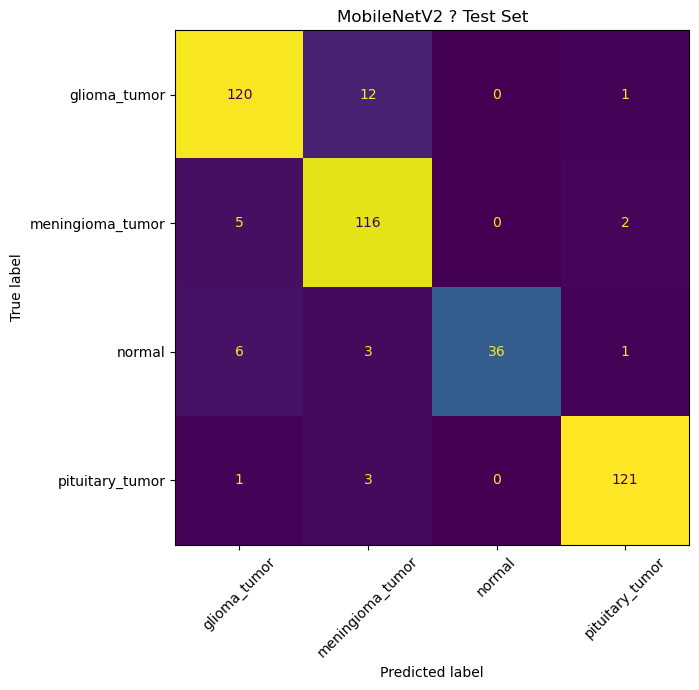

In [7]:
cm=confusion_matrix(all_labels,all_predictions,labels=list(range(len(class_names))))
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
fig,ax=plt.subplots(figsize=(8,7))
disp.plot(ax=ax,xticks_rotation=45,values_format="d",colorbar=False)
ax.set_title("MobileNetV2 ? Test Set")
plt.tight_layout()
plt.show()


## 7. Optional: save predictions for later comparison


## 8. Inspect misclassified images

This lists every test image whose predicted class differs from its true class and displays the images for visual inspection.


Misclassified images: 34 of 427


,filepath,true_label,predicted_label,confidence
385,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.989125
273,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.985944
112,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.984876
122,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,glioma_tumor,0.977878
71,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,glioma_tumor,0.974767
285,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,glioma_tumor,0.970431
329,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.964233
31,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,meningioma_tumor,0.962834
73,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,glioma_tumor,0.945355
256,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,normal,glioma_tumor,0.932028


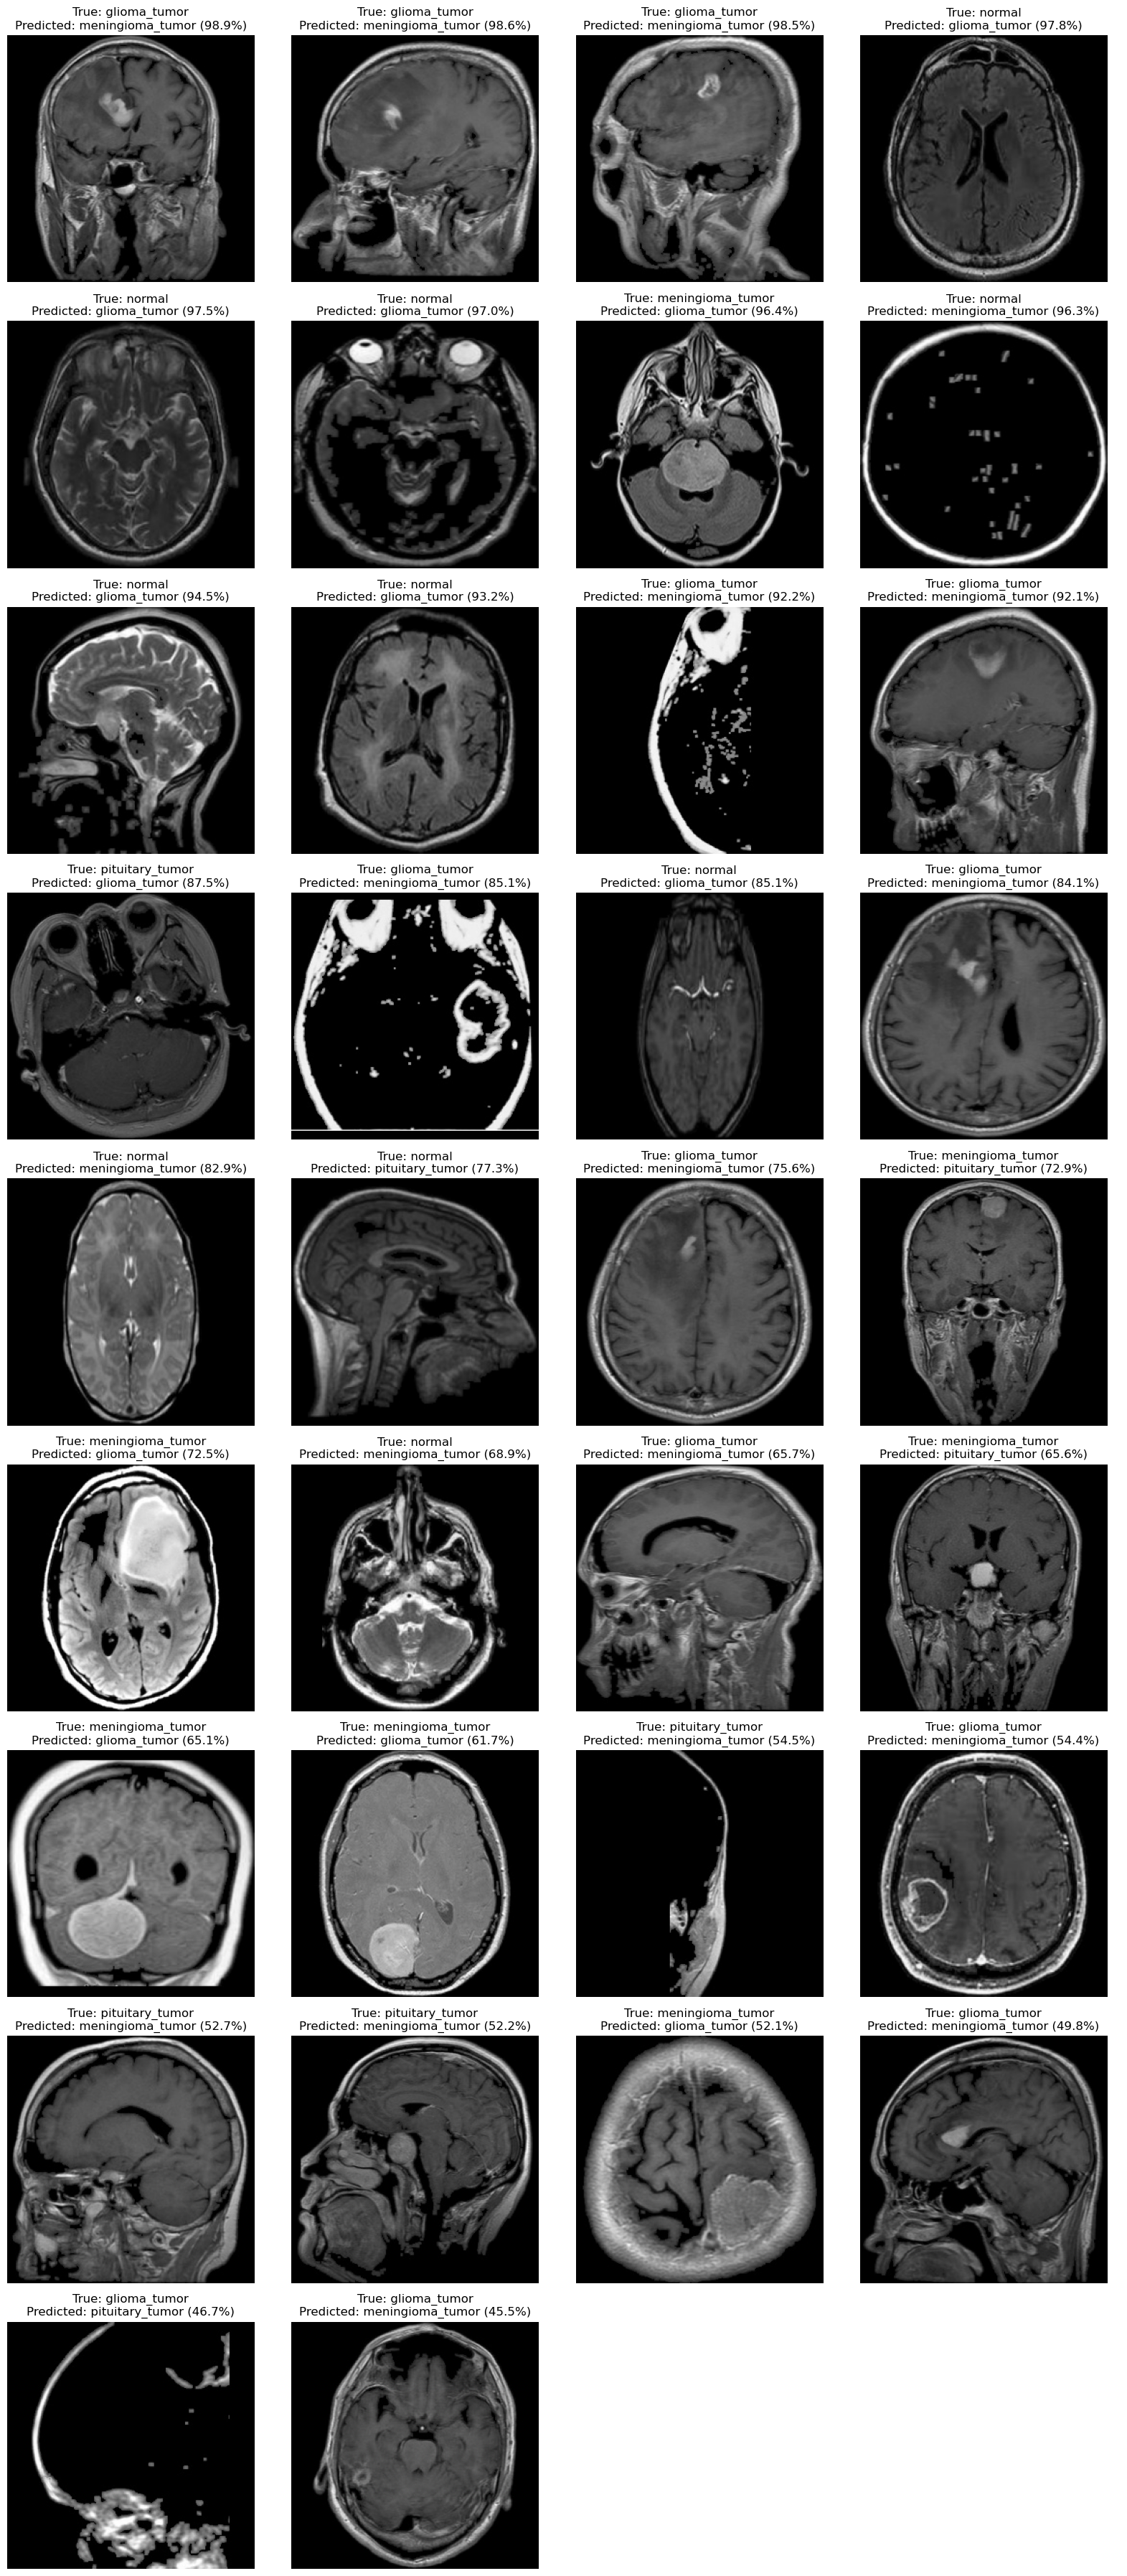

In [8]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["confidence"]=all_confidences
misclassified_df=results_df[results_df["true_label"]!=results_df["predicted_label"]].copy()
misclassified_df=misclassified_df.sort_values("confidence",ascending=False)
print(f"Misclassified images: {len(misclassified_df)} of {len(results_df)}")
display(misclassified_df[["filepath","true_label","predicted_label","confidence"]])
misclassified_df.to_csv(Path("../trained_models")/"mobilenet_v2_misclassified_images.csv",index=False)
columns=4
rows=(len(misclassified_df)+columns-1)//columns
if rows:
    fig,axes=plt.subplots(rows,columns,figsize=(16,4*rows))
    axes=np.atleast_1d(axes).ravel()
    for ax,(_,row) in zip(axes,misclassified_df.iterrows()):
        image=Image.open(row["filepath"])
        ax.imshow(image,cmap="gray")
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']} ({row['confidence']:.1%})")
        ax.axis("off")
    for ax in axes[len(misclassified_df):]: ax.axis("off")
    plt.tight_layout()
    plt.show()


In [9]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["correct"]=results_df["true_label"]==results_df["predicted_label"]
prediction_path=Path("../trained_models")/"mobilenet_v2_test_predictions.csv"
prediction_path.parent.mkdir(parents=True,exist_ok=True)
results_df.to_csv(prediction_path,index=False)
print("Saved test predictions to:",prediction_path.resolve())


Saved test predictions to: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\Smaller_Dataset\trained_models\mobilenet_v2_test_predictions.csv
